In [1]:
# %%
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
import pandas as pd

# 1. Carrega os arquivos CSV
df_items_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_items_dataset.csv')
df_pedidos = pd.read_csv('../../Dados/Brazilian Logistic/olist_orders_dataset.csv')
df_pagamentos_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_payments_dataset.csv')
df_revisoes_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_reviews_dataset.csv')
df_produtos = pd.read_csv('../../Dados/Brazilian Logistic/olist_products_dataset.csv')
df_geolocalizacao = pd.read_csv('../../Dados/Brazilian Logistic/olist_geolocation_dataset.csv')
df_clientes = pd.read_csv('../../Dados/Brazilian Logistic/olist_customers_dataset.csv')
df_vendedores = pd.read_csv('../../Dados/Brazilian Logistic/olist_sellers_dataset.csv')

# %%
# Problema: Alguns pedidos possuem mais de um vendedor, o que pode gerar inconsistências na análise de reviews.
# Para garantir que cada pedido seja associado a apenas um vendedor, filtramos os pedidos que possuem apenas um vendedor.

df_items_pedido_filtrado = df_items_pedido.groupby('order_id').filter(lambda x: x['seller_id'].nunique() == 1)
df_items_pedido_filtrado['qtd_items'] = df_items_pedido_filtrado.groupby('order_id')['order_id'].transform('count')

# ALTERAÇÃO: calcula o total dos itens antes do merge com pagamentos,
# para que pedidos com vários pagamentos não tenham o preço e o frete somados repetidamente.
totais_itens = df_items_pedido_filtrado.groupby('order_id').apply(
    lambda x: (x['price'] + x['freight_value']).sum()
).rename('total_price_value').reset_index()

df = df_items_pedido_filtrado.merge(df_revisoes_pedido.drop_duplicates(subset='order_id', keep='last'), how='left', on='order_id')
df = df.merge(df_pagamentos_pedido, how='inner', on='order_id')
df = df.rename(columns={'payment_value': 'total_payment_value'})
df = df.merge(totais_itens, how='left', on='order_id')
df = df.merge(df_pedidos, how='left', on='order_id')
df = df.merge(df_produtos, how='left', on='product_id')

# ==============================================================================
# 🛠️ BLOCO DE DATAS AJUSTADO COM OS CONCEITOS CORRETOS DO DATASET
# ==============================================================================
# Convertemos temporariamente para datetime para realizar os cálculos matemáticos
data_entrega_cliente = pd.to_datetime(df['order_delivered_customer_date'], errors='coerce')
data_postagem_transportadora = pd.to_datetime(df['order_delivered_carrier_date'], errors='coerce')
data_estimada = pd.to_datetime(df['order_estimated_delivery_date'], errors='coerce')

# 1. Calcular o tempo de trânsito real (Diferença entre entrega ao cliente e postagem)
df['diferenca_data_entrega_vendedor_cliente'] = (data_entrega_cliente - data_postagem_transportadora).dt.days

# CORREÇÃO: Uso do .dropna() para extrair a média correta do tempo de transporte
media_transito = df['diferenca_data_entrega_vendedor_cliente'].dropna().mean()
media_transito_round = round(media_transito) if pd.notnull(media_transito) else 7

# 2. Imputar a data de postagem se o cliente recebeu o produto, mas a transportadora não registrou o envio
# Estimativa: Data de Entrega do Cliente Menos a Média de Dias em Trânsito
condicao = (data_postagem_transportadora.isnull() & data_entrega_cliente.notnull())
data_postagem_transportadora[condicao] = data_entrega_cliente[condicao] - pd.Timedelta(days=media_transito_round)

# Devolvemos a data tratada para o dataframe original em formato string
df['order_delivered_carrier_date'] = data_postagem_transportadora.dt.strftime('%Y-%m-%d %H:%M:%S')

# CORREÇÃO LOGÍSTICA: O atraso real do pedido é calculado pela chegada no CLIENTE versus a Estimativa prometida
df['dias_atraso'] = (data_entrega_cliente - data_estimada).dt.days
# ==============================================================================

# Remove pedidos que não possuem nem comentários nem registro de data de entrega, e remove avaliações duplicadas, evitando viés nos dados.
# Tratar avaliações repetidas, filtrando pela avaliação mais longa
df['review_comment'] = df['review_comment_title'].fillna("") + ': ' + df['review_comment_message'].fillna("")
df['review_char_length'] = df['review_comment'].str.len()
df = df.sort_values('review_char_length', ascending=False).drop_duplicates('order_id', keep='first')
df = df[(df['review_char_length'] > 2) | (df['order_delivered_carrier_date'].notna() | df['order_delivered_customer_date'].notna())]

# 2. Normalizar os CEPs para garantir correspondência
def normalizar_cep(coluna):
    return (coluna.astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(5))

df_geolocalizacao['geolocation_zip_code_prefix'] = normalizar_cep(df_geolocalizacao['geolocation_zip_code_prefix'])
df_clientes['customer_zip_code_prefix'] = normalizar_cep(df_clientes['customer_zip_code_prefix'])
df_vendedores['seller_zip_code_prefix'] = normalizar_cep(df_vendedores['seller_zip_code_prefix'])

# 3. Agrupar geolocalização por CEP
# Evita duplicações de linhas no merge
df_geo = df_geolocalizacao.groupby('geolocation_zip_code_prefix', as_index=False).agg({'geolocation_lat': 'mean', 'geolocation_lng': 'mean'})

# 2. Integração de CEPs (Clientes e Vendedores)
df = df.merge(df_clientes[['customer_id', 'customer_zip_code_prefix']], on='customer_id', how='left')
df = df.merge(df_vendedores[['seller_id', 'seller_zip_code_prefix']], on='seller_id', how='left')

df = df.merge(df_geo.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix', 'geolocation_lat': 'customer_latitude', 'geolocation_lng': 'customer_longitude'}), on='customer_zip_code_prefix', how='left')
df = df.merge(df_geo.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix', 'geolocation_lat': 'seller_latitude', 'geolocation_lng': 'seller_longitude'}), on='seller_zip_code_prefix', how='left')

# Preenchendo valores de latitude e longitude de cliente vazios com base no zip code
# 1. Criar dicionários de mapeamento direto a partir do df_geo (Busca indexada com O(1) de complexidade)
mapa_lat = df_geo.set_index('geolocation_zip_code_prefix')['geolocation_lat'].to_dict()
mapa_lng = df_geo.set_index('geolocation_zip_code_prefix')['geolocation_lng'].to_dict()

# 2. Preencher os valores nulos mapeando os CEPs diretamente de forma vetorizada
df['customer_latitude'] = df['customer_latitude'].fillna(df['customer_zip_code_prefix'].map(mapa_lat))
df['customer_longitude'] = df['customer_longitude'].fillna(df['customer_zip_code_prefix'].map(mapa_lng))

df.to_csv('order_items_reviews_filtered.csv', index=False)

order_id                                       0
order_item_id                                  0
product_id                                     0
seller_id                                      0
shipping_limit_date                            0
price                                          0
freight_value                                  0
qtd_items                                      0
review_id                                    717
review_score                                 717
review_comment_title                       85668
review_comment_message                     57491
review_creation_date                         717
review_answer_timestamp                      717
payment_sequential                             0
payment_type                                   0
payment_installments                           0
total_payment_value                            0
total_price_value                              0
customer_id                                    0
order_status        

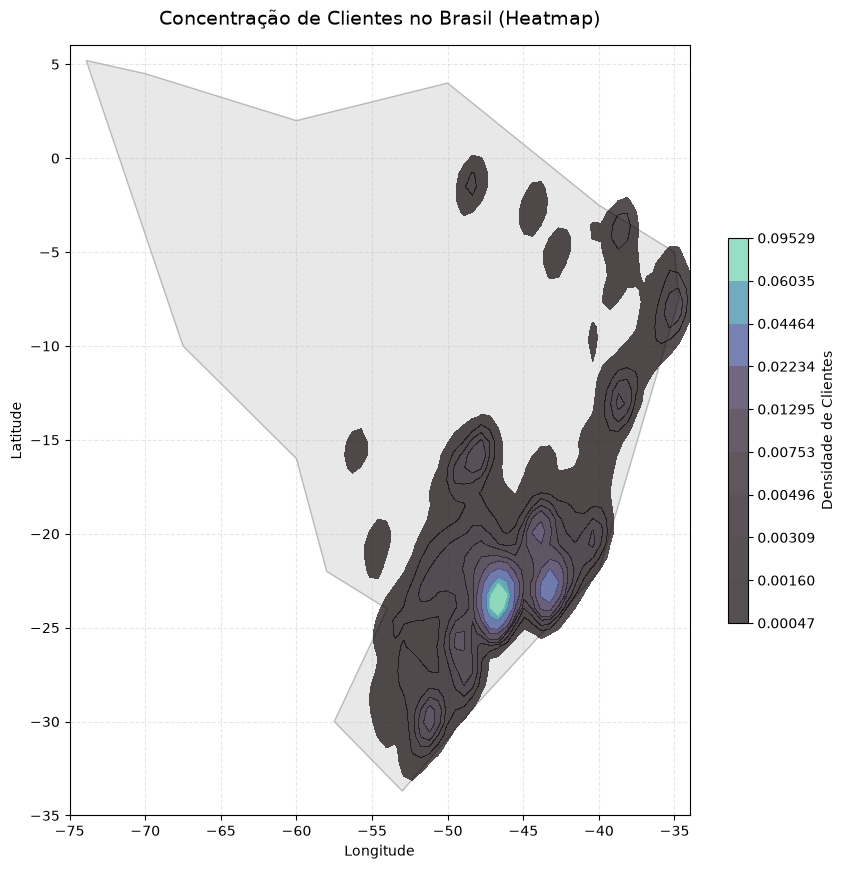

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Dados de exemplo limpos (X = Longitude, Y = Latitude)
print(df.isna().sum())
df_geo = df[["customer_longitude", "customer_latitude"]].dropna()

# 2. Configura a figura e o eixo
fig, ax = plt.subplots(figsize=(10, 10))
br_outline_x = [-73.9, -70.0, -60.0, -50.0, -40.0, -35.0, -34.7, -40.0, -48.0, -53.0, -57.5, -54.0, -58.0, -60.0, -67.5, -73.9]
br_outline_y = [ 5.2,   4.5,   2.0,   4.0,  -2.5,  -5.0,  -7.5, -22.0, -29.0, -33.7, -30.0, -24.0, -22.0, -16.0,  -10.0,   5.2]
ax.fill(br_outline_x, br_outline_y, color="lightgray", edgecolor="gray", alpha=0.5, zorder=1)

# 4. Plota o mapa de calor por cima (zorder=2 garante que fica em cima do fundo)
sns.kdeplot(
    data=df_geo,
    x="customer_longitude",
    y="customer_latitude",
    gridsize=120,
    fill=True,
    thresh=0.06,
    cmap="mako",
    alpha=0.7,   # Opacidade para permitir ver as linhas do mapa abaixo
    cbar=True,
    cbar_kws={"label": "Densidade de Clientes", "shrink": 0.5},
    ax=ax,
    zorder=2
)

# 5. Ajustes visuais e limites geográficos exatos do Brasil
plt.title("Concentração de Clientes no Brasil (Heatmap)", fontsize=14, pad=15)
plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Trava o zoom do Matplotlib nos limites do território brasileiro
ax.set_xlim(-75, -34)
ax.set_ylim(-35, 6)
ax.grid(True, linestyle="--", alpha=0.3, zorder=0)

plt.show()


In [ ]:


# Treinar uma RNN (LSTM no caso) para classificar comentários como: no prazo ou atrasado
# código...

# Embora os cálculos de dias de atraso estimem prazo, o cliente pode ter recebido antes ou depois, portanto, sobrescreveremos pela classificação da LSTM
def classify_review(row):
    return LSTM.predict(row['review_comment']) if row['review_char_length'] > 2 else row['status_entrega']
NO_PRAZO = 0
ATRASADO = 1
NAO_INFORMADO = 2
df['status_entrega'] = df.apply(lambda row: NO_PRAZO if row['dias_atraso'] <= 0 else ATRASADO if row['dias_atraso'] > 0 else NAO_INFORMADO, axis=1)
df['status_entrega'] = df.apply(classify_review, axis=1)


# Treinar uma ML (supervisionada) para identificar padrões prazo pela distancia entre vendedor e comprador 
# código

# Treinar 6 clusters (IA não supervisionada) para classificar prazo por regiões do brasil
# código


